C:\Users\congc\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


cpu


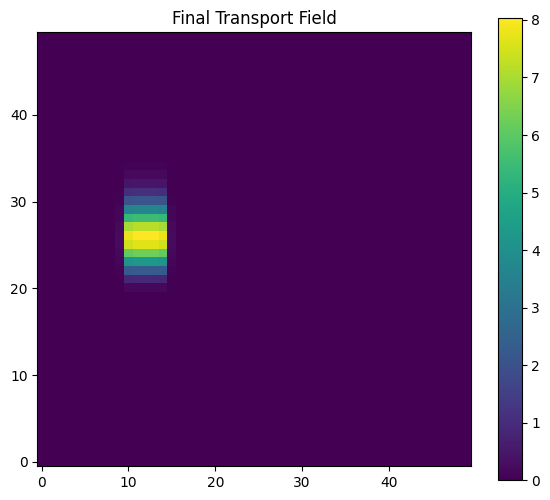

(100, 2500)
(100, 50)
Epoch: 0 Loss: 0.0
Epoch: 500 Loss: 0.0
Epoch: 1000 Loss: 0.0
Epoch: 1500 Loss: 0.0


KeyboardInterrupt: 

In [1]:
# =====================================================
# IMPORTS
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics.pairwise import euclidean_distances

from numpy.linalg import cond

# =====================================================
# DEVICE
# =====================================================

device = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"
)

print(device)

# =====================================================
# GRID
# =====================================================

nx = 50
ny = 50

N = nx * ny

dx = 1
dy = 1

# =====================================================
# PDE PARAMETERS
# =====================================================

D = 0.03

v_x = 4.0

dt = 0.01

nt = 100

# =====================================================
# INDEX FUNCTION
# =====================================================

def idx(i,j):

    return i * ny + j

# =====================================================
# INITIAL FIELD
# =====================================================

u = np.zeros((nx,ny))

u[20:25,10:15] = 10

# =====================================================
# SAVE TIME EVOLUTION
# =====================================================

fields_over_time = []

fields_over_time.append(
    u.copy()
)

# =====================================================
# TRUE TRANSPORT OPERATOR
# =====================================================

T_true = np.zeros((N,N))

for i in range(1,nx-1):

    for j in range(1,ny-1):

        center = idx(i,j)

        # ---------------------------------------------
        # finite difference transport operator
        # ---------------------------------------------

        self_weight = (

            1

            -

            v_x * dt / dx

            -

            4 * D * dt
        )

        adv_weight = (

            v_x * dt / dx

            +

            D * dt
        )

        diff_weight = D * dt

        # ---------------------------------------------
        # assign
        # ---------------------------------------------

        T_true[center,center] = self_weight

        # transport direction

        T_true[center,idx(i-1,j)] = adv_weight

        # diffusion

        T_true[center,idx(i+1,j)] = diff_weight

        T_true[center,idx(i,j+1)] = diff_weight

        T_true[center,idx(i,j-1)] = diff_weight

# =====================================================
# PDE EVOLUTION
# =====================================================

for t in range(nt):

    u_vec = u.reshape(-1)

    u_next = np.matmul(

        T_true,

        u_vec
    )

    u = u_next.reshape(nx,ny)

    fields_over_time.append(
        u.copy()
    )

# =====================================================
# FINAL FIELD
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u,
    origin="lower"
)

plt.title(
    "Final Transport Field"
)

plt.colorbar()

plt.show()

# =====================================================
# TRUE TRANSPORT-INDUCED EXPOSURE MAPPINGS
# =====================================================

E_true = []

for t in range(len(fields_over_time)-1):

    current_field = fields_over_time[t]

    exposure = np.matmul(

        T_true,

        current_field.reshape(-1)
    )

    E_true.append(
        exposure
    )

E_true = np.array(E_true)

print(E_true.shape)

# =====================================================
# GAUSSIAN MAPPINGS
# =====================================================

coords = []

for i in range(nx):

    for j in range(ny):

        coords.append([i,j])

coords = np.array(coords)

dist_matrix = euclidean_distances(coords)

sigma = 4

W_gaussian = np.exp(

    -(dist_matrix**2)/(2*sigma**2)
)

W_gaussian = (

    W_gaussian

    /

    W_gaussian.sum(
        axis=1,
        keepdims=True
    )
)

E_gaussian = []

for t in range(len(fields_over_time)-1):

    exposure = np.matmul(

        W_gaussian,

        fields_over_time[t].reshape(-1)
    )

    E_gaussian.append(
        exposure
    )

E_gaussian = np.array(
    E_gaussian
)

# =====================================================
# TEMPORAL DATASET
# =====================================================

U_t = []

U_next = []

for t in range(len(fields_over_time)-1):

    current_field = fields_over_time[t]

    next_field = fields_over_time[t+1]

    U_t.append(

        current_field.reshape(-1)
    )

    U_next.append(

        next_field.reshape(-1)
    )

U_t = np.array(U_t)

U_next = np.array(U_next)

# =====================================================
# SPARSE MONITORING
# =====================================================

np.random.seed(123)

n_monitors = 50

monitor_idx = np.random.choice(

    N,

    size=n_monitors,

    replace=False
)

U_t_sparse = U_t[:,monitor_idx]

U_next_sparse = U_next[:,monitor_idx]

print(U_t_sparse.shape)

# =====================================================
# TORCH DATA
# =====================================================

U_t_torch = torch.tensor(

    U_t,

    dtype=torch.float32
).to(device)

U_next_torch = torch.tensor(

    U_next,

    dtype=torch.float32
).to(device)

# =====================================================
# LEARNABLE OPERATOR
# =====================================================

T_param = nn.Parameter(

    0.001 * torch.randn(N,N)
)

optimizer = optim.Adam(

    [T_param],

    lr=0.001
)

# =====================================================
# LOCALITY MASK
# =====================================================

local_mask = np.zeros((N,N))

for i in range(nx):

    for j in range(ny):

        center = idx(i,j)

        neighbors = [

            (i,j),

            (i+1,j),

            (i-1,j),

            (i,j+1),

            (i,j-1)
        ]

        for ni,nj in neighbors:

            if (

                0 <= ni < nx

                and

                0 <= nj < ny
            ):

                local_mask[

                    center,

                    idx(ni,nj)

                ] = 1

local_mask = torch.tensor(

    local_mask,

    dtype=torch.float32
).to(device)

# =====================================================
# TRAINING
# =====================================================

epochs = 3000

loss_history = []

for epoch in range(epochs):

    optimizer.zero_grad()

    # ---------------------------------------------
    # locality
    # ---------------------------------------------

    T_local = (

        T_param

        *

        local_mask
    )

    # ---------------------------------------------
    # positivity
    # ---------------------------------------------

    T_positive = torch.relu(
        T_local
    )

    # ---------------------------------------------
    # row normalization
    # ---------------------------------------------

    row_sums = (

        T_positive.sum(
            dim=1,
            keepdim=True
        )

        +

        1e-6
    )

    T_norm = (

        T_positive

        /

        row_sums
    )

    # ---------------------------------------------
    # dynamic prediction
    # ---------------------------------------------

    U_pred = torch.matmul(

        U_t_torch,

        T_norm.T
    )

    # ---------------------------------------------
    # sparse monitor loss
    # ---------------------------------------------

    U_pred_sparse = U_pred[:,monitor_idx]

    U_next_sparse_torch = U_next_torch[:,monitor_idx]

    loss_temporal = torch.mean(

        (
            U_pred_sparse

            -

            U_next_sparse_torch
        )**2
    )

    # ---------------------------------------------
    # sparsity penalty
    # ---------------------------------------------

    loss_sparse = torch.mean(
        torch.abs(T_norm)
    )

    # ---------------------------------------------
    # total loss
    # ---------------------------------------------

    loss = (

        loss_temporal

        +

        0.0001 * loss_sparse
    )

    loss.backward()

    optimizer.step()

    loss_history.append(
        loss.item()
    )

    if epoch % 500 == 0:

        print(

            "Epoch:", epoch,

            "Loss:", round(loss.item(),6)
        )

# =====================================================
# FINAL LEARNED OPERATOR
# =====================================================

T_learned = (

    T_norm

    .detach()

    .cpu()

    .numpy()
)

# =====================================================
# LEARNED MAPPINGS
# =====================================================

E_learned = []

for t in range(len(fields_over_time)-1):

    exposure = np.matmul(

        T_learned,

        fields_over_time[t].reshape(-1)
    )

    E_learned.append(
        exposure
    )

E_learned = np.array(
    E_learned
)

# =====================================================
# MAPPING RMSE
# =====================================================

rmse_gaussian = np.sqrt(

    np.mean(

        (
            E_true

            -

            E_gaussian
        )**2
    )
)

rmse_learned = np.sqrt(

    np.mean(

        (
            E_true

            -

            E_learned
        )**2
    )
)

print()

print("Gaussian Mapping RMSE:")

print(round(rmse_gaussian,4))

print()

print("Learned Mapping RMSE:")

print(round(rmse_learned,4))

# =====================================================
# OPERATOR RECOVERY
# =====================================================

fro_error_gaussian = (

    np.linalg.norm(

        T_true

        -

        W_gaussian,

        ord="fro"
    )

    /

    np.linalg.norm(
        T_true,
        ord="fro"
    )
)

fro_error_learned = (

    np.linalg.norm(

        T_true

        -

        T_learned,

        ord="fro"
    )

    /

    np.linalg.norm(
        T_true,
        ord="fro"
    )
)

print()

print("Gaussian Operator Error:")

print(round(fro_error_gaussian,4))

print()

print("Learned Operator Error:")

print(round(fro_error_learned,4))

# =====================================================
# OPERATOR CORRELATION
# =====================================================

corr_gaussian = np.corrcoef(

    T_true.flatten(),

    W_gaussian.flatten()
)[0,1]

corr_learned = np.corrcoef(

    T_true.flatten(),

    T_learned.flatten()
)[0,1]

print()

print("Gaussian Correlation:")

print(round(corr_gaussian,4))

print()

print("Learned Correlation:")

print(round(corr_learned,4))

# =====================================================
# CONDITION NUMBERS
# =====================================================

cond_gaussian = cond(

    W_gaussian + 1e-6*np.eye(N)
)

cond_learned = cond(

    T_learned + 1e-6*np.eye(N)
)

print()

print("Gaussian Condition Number:")

print(round(cond_gaussian,4))

print()

print("Learned Condition Number:")

print(round(cond_learned,4))

In [2]:
# =====================================================
# FAST STRUCTURED OPERATOR LEARNING
# =====================================================

fast_results = []

# =====================================================
# SETTINGS
# =====================================================

monitor_grid = [

    100,
    50,
    20,
    10
]

sigma_grid = [

    2,
    4,
    8,
    16
]

# =====================================================
# STRUCTURED PARAMETERS
# =====================================================

for sigma in sigma_grid:

    print()

    print("===================================")

    print("SIGMA:", sigma)

    print("===================================")

    # -------------------------------------------------
    # GAUSSIAN OPERATOR
    # -------------------------------------------------

    W_gaussian = np.exp(

        -(dist_matrix**2)/(2*sigma**2)
    )

    W_gaussian = (

        W_gaussian

        /

        W_gaussian.sum(
            axis=1,
            keepdims=True
        )
    )

    # -------------------------------------------------
    # GAUSSIAN METRICS
    # -------------------------------------------------

    gaussian_error = (

        np.linalg.norm(

            T_true

            -

            W_gaussian,

            ord="fro"
        )

        /

        np.linalg.norm(
            T_true,
            ord="fro"
        )
    )

    gaussian_corr = np.corrcoef(

        T_true.flatten(),

        W_gaussian.flatten()
    )[0,1]

    gaussian_cond = cond(

        W_gaussian + 1e-6*np.eye(N)
    )

    # =================================================
    # MONITOR LOOP
    # =================================================

    for n_monitors in monitor_grid:

        print()

        print("Monitors:", n_monitors)

        # ---------------------------------------------
        # MONITORS
        # ---------------------------------------------

        np.random.seed(123)

        monitor_idx = np.random.choice(

            N,

            size=n_monitors,

            replace=False
        )

        # ---------------------------------------------
        # STRUCTURED TRANSPORT PARAMETERS
        # ---------------------------------------------

        theta_self = nn.Parameter(
            torch.tensor(0.7)
        )

        theta_adv = nn.Parameter(
            torch.tensor(0.2)
        )

        theta_diff = nn.Parameter(
            torch.tensor(0.05)
        )

        optimizer = optim.Adam(

            [
                theta_self,
                theta_adv,
                theta_diff
            ],

            lr=0.01
        )

        # ---------------------------------------------
        # TRAINING
        # ---------------------------------------------

        epochs = 500

        for epoch in range(epochs):

            optimizer.zero_grad()

            # -----------------------------------------
            # BUILD STRUCTURED OPERATOR
            # -----------------------------------------

            T_struct = torch.zeros(

                (N,N),

                dtype=torch.float32
            ).to(device)

            for i in range(1,nx-1):

                for j in range(1,ny-1):

                    center = idx(i,j)

                    T_struct[
                        center,
                        center
                    ] = torch.relu(theta_self)

                    T_struct[
                        center,
                        idx(i-1,j)
                    ] = torch.relu(theta_adv)

                    T_struct[
                        center,
                        idx(i+1,j)
                    ] = torch.relu(theta_diff)

                    T_struct[
                        center,
                        idx(i,j+1)
                    ] = torch.relu(theta_diff)

                    T_struct[
                        center,
                        idx(i,j-1)
                    ] = torch.relu(theta_diff)

            # -----------------------------------------
            # NORMALIZE
            # -----------------------------------------

            row_sums = (

                T_struct.sum(
                    dim=1,
                    keepdim=True
                )

                +

                1e-6
            )

            T_struct = (

                T_struct

                /

                row_sums
            )

            # -----------------------------------------
            # PREDICT
            # -----------------------------------------

            U_pred = torch.matmul(

                U_t_torch,

                T_struct.T
            )

            U_pred_sparse = U_pred[:,monitor_idx]

            U_next_sparse = U_next_torch[:,monitor_idx]

            # -----------------------------------------
            # LOSS
            # -----------------------------------------

            loss = torch.mean(

                (
                    U_pred_sparse

                    -

                    U_next_sparse
                )**2
            )

            loss.backward()

            optimizer.step()

        # ---------------------------------------------
        # FINAL OPERATOR
        # ---------------------------------------------

        T_final = (

            T_struct

            .detach()

            .cpu()

            .numpy()
        )

        # ---------------------------------------------
        # METRICS
        # ---------------------------------------------

        operator_error = (

            np.linalg.norm(

                T_true

                -

                T_final,

                ord="fro"
            )

            /

            np.linalg.norm(
                T_true,
                ord="fro"
            )
        )

        operator_corr = np.corrcoef(

            T_true.flatten(),

            T_final.flatten()
        )[0,1]

        operator_cond = cond(

            T_final + 1e-6*np.eye(N)
        )

        # ---------------------------------------------
        # SAVE
        # ---------------------------------------------

        fast_results.append({

            "sigma": sigma,

            "monitors": n_monitors,

            "gaussian_error":
                gaussian_error,

            "structured_error":
                operator_error,

            "gaussian_corr":
                gaussian_corr,

            "structured_corr":
                operator_corr,

            "gaussian_condition":
                gaussian_cond,

            "structured_condition":
                operator_cond,

            "theta_self":
                theta_self.item(),

            "theta_adv":
                theta_adv.item(),

            "theta_diff":
                theta_diff.item()
        })

# =====================================================
# RESULTS
# =====================================================

fast_df = pd.DataFrame(
    fast_results
)

print()

print(fast_df.head())

# =====================================================
# SAVE
# =====================================================

fast_df.to_csv(

    "fast_operator_results.csv",

    index=False
)

print()

print("Saved:")
print("fast_operator_results.csv")


SIGMA: 2

Monitors: 100


KeyboardInterrupt: 

In [3]:
# =====================================================
# FAST VECTORIZED STRUCTURED OPERATOR
# =====================================================

# ---------------------------------------------
# EDGE LISTS
# ---------------------------------------------

center_idx = []
left_idx = []
right_idx = []
up_idx = []
down_idx = []

for i in range(1,nx-1):

    for j in range(1,ny-1):

        center = idx(i,j)

        center_idx.append(center)

        left_idx.append(idx(i-1,j))

        right_idx.append(idx(i+1,j))

        up_idx.append(idx(i,j+1))

        down_idx.append(idx(i,j-1))

center_idx = torch.tensor(center_idx).to(device)

left_idx = torch.tensor(left_idx).to(device)

right_idx = torch.tensor(right_idx).to(device)

up_idx = torch.tensor(up_idx).to(device)

down_idx = torch.tensor(down_idx).to(device)

# =====================================================
# PARAMETERS
# =====================================================

theta_self = nn.Parameter(
    torch.tensor(0.7).to(device)
)

theta_adv = nn.Parameter(
    torch.tensor(0.2).to(device)
)

theta_diff = nn.Parameter(
    torch.tensor(0.05).to(device)
)

optimizer = optim.Adam(

    [
        theta_self,
        theta_adv,
        theta_diff
    ],

    lr=0.01
)

# =====================================================
# TRAINING
# =====================================================

epochs = 300

for epoch in range(epochs):

    optimizer.zero_grad()

    # ---------------------------------------------
    # BUILD SPARSE OPERATOR
    # ---------------------------------------------

    T_struct = torch.zeros(

        (N,N),

        device=device
    )

    T_struct[
        center_idx,
        center_idx
    ] = torch.relu(theta_self)

    T_struct[
        center_idx,
        left_idx
    ] = torch.relu(theta_adv)

    T_struct[
        center_idx,
        right_idx
    ] = torch.relu(theta_diff)

    T_struct[
        center_idx,
        up_idx
    ] = torch.relu(theta_diff)

    T_struct[
        center_idx,
        down_idx
    ] = torch.relu(theta_diff)

    # ---------------------------------------------
    # NORMALIZE
    # ---------------------------------------------

    row_sums = (

        T_struct.sum(
            dim=1,
            keepdim=True
        )

        +

        1e-6
    )

    T_struct = (

        T_struct

        /

        row_sums
    )

    # ---------------------------------------------
    # PREDICT
    # ---------------------------------------------

    U_pred = torch.matmul(

        U_t_torch,

        T_struct.T
    )

    U_pred_sparse = U_pred[:,monitor_idx]

    U_next_sparse = U_next_torch[:,monitor_idx]

    # ---------------------------------------------
    # LOSS
    # ---------------------------------------------

    loss = torch.mean(

        (
            U_pred_sparse

            -

            U_next_sparse
        )**2
    )

    loss.backward()

    optimizer.step()

    # ---------------------------------------------
    # PRINT
    # ---------------------------------------------

    if epoch % 50 == 0:

        print(

            "Epoch:",
            epoch,

            "Loss:",
            round(loss.item(),6)
        )

# =====================================================
# FINAL OPERATOR
# =====================================================

T_final = (

    T_struct

    .detach()

    .cpu()

    .numpy()
)

Epoch: 0 Loss: 0.000509
Epoch: 50 Loss: 2.4e-05
Epoch: 100 Loss: 4e-06
Epoch: 150 Loss: 0.0
Epoch: 200 Loss: 0.0
Epoch: 250 Loss: 0.0


In [6]:
# =====================================================
# STRUCTURED TRANSPORT SENSITIVITY
# =====================================================
import pandas as pd
structured_results = []

# =====================================================
# SETTINGS
# =====================================================

adv_grid = [

    0.1,
    0.6
]

diff_grid = [

    0.01,
    0.10
]

monitor_grid = [

    100,
    10
]

sigma_grid = [

    2,
    16
]

# =====================================================
# COORDINATES
# =====================================================

coords = []

for i in range(nx):

    for j in range(ny):

        coords.append([i,j])

coords = np.array(coords)

dist_matrix = euclidean_distances(coords)

# =====================================================
# MAIN LOOP
# =====================================================

for theta_adv_true in adv_grid:

    for theta_diff_true in diff_grid:

        print()

        print("===================================")

        print("ADV:", theta_adv_true)

        print("DIFF:", theta_diff_true)

        print("===================================")

        # =================================================
        # TRUE OPERATOR
        # =================================================

        T_true_struct = np.zeros((N,N))

        theta_self_true = (

            1

            -

            theta_adv_true

            -

            3 * theta_diff_true
        )

        for i in range(1,nx-1):

            for j in range(1,ny-1):

                center = idx(i,j)

                T_true_struct[
                    center,
                    center
                ] = theta_self_true

                # directional transport

                T_true_struct[
                    center,
                    idx(i-1,j)
                ] = theta_adv_true

                # diffusion

                T_true_struct[
                    center,
                    idx(i+1,j)
                ] = theta_diff_true

                T_true_struct[
                    center,
                    idx(i,j+1)
                ] = theta_diff_true

                T_true_struct[
                    center,
                    idx(i,j-1)
                ] = theta_diff_true

        # =================================================
        # GENERATE TRANSPORT DYNAMICS
        # =================================================

        u = np.zeros((nx,ny))

        u[20:25,10:15] = 10

        fields_over_time = []

        fields_over_time.append(
            u.copy()
        )

        nt = 100

        for t in range(nt):

            u_vec = u.reshape(-1)

            u_next = np.matmul(

                T_true_struct,

                u_vec
            )

            u = u_next.reshape(nx,ny)

            fields_over_time.append(
                u.copy()
            )

        # =================================================
        # TEMPORAL DATA
        # =================================================

        U_t = []

        U_next = []

        for t in range(len(fields_over_time)-1):

            current_field = fields_over_time[t]

            next_field = fields_over_time[t+1]

            U_t.append(

                current_field.reshape(-1)
            )

            U_next.append(

                next_field.reshape(-1)
            )

        U_t = np.array(U_t)

        U_next = np.array(U_next)

        # =================================================
        # TORCH DATA
        # =================================================

        U_t_torch = torch.tensor(

            U_t,

            dtype=torch.float32
        ).to(device)

        U_next_torch = torch.tensor(

            U_next,

            dtype=torch.float32
        ).to(device)

        # =================================================
        # TRUE EXPOSURE
        # =================================================

        E_true_struct = []

        for t in range(len(fields_over_time)-1):

            exposure = np.matmul(

                T_true_struct,

                fields_over_time[t].reshape(-1)
            )

            E_true_struct.append(
                exposure
            )

        E_true_struct = np.array(
            E_true_struct
        )

        # =================================================
        # GAUSSIAN LOOP
        # =================================================

        for sigma in sigma_grid:

            print()

            print("Sigma:", sigma)

            # -------------------------------------------------
            # GAUSSIAN OPERATOR
            # -------------------------------------------------

            W_gaussian = np.exp(

                -(dist_matrix**2)/(2*sigma**2)
            )

            W_gaussian = (

                W_gaussian

                /

                W_gaussian.sum(
                    axis=1,
                    keepdims=True
                )
            )

            # -------------------------------------------------
            # GAUSSIAN EXPOSURE
            # -------------------------------------------------

            E_gaussian = []

            for t in range(len(fields_over_time)-1):

                exposure = np.matmul(

                    W_gaussian,

                    fields_over_time[t].reshape(-1)
                )

                E_gaussian.append(
                    exposure
                )

            E_gaussian = np.array(
                E_gaussian
            )

            # -------------------------------------------------
            # GAUSSIAN METRICS
            # -------------------------------------------------

            gaussian_rmse = np.sqrt(

                np.mean(

                    (
                        E_true_struct

                        -

                        E_gaussian
                    )**2
                )
            )

            gaussian_corr = np.corrcoef(

                T_true_struct.flatten(),

                W_gaussian.flatten()
            )[0,1]

            gaussian_cond = cond(

                W_gaussian + 1e-6*np.eye(N)
            )

            # -------------------------------------------------
            # EFFECTIVE RANK
            # -------------------------------------------------

            singular_vals = np.linalg.svd(

                W_gaussian,

                compute_uv=False
            )

            effective_rank = np.sum(

                singular_vals > 1e-3
            )

            # =================================================
            # MONITOR LOOP
            # =================================================

            for n_monitors in monitor_grid:

                print(

                    "Monitors:",
                    n_monitors
                )

                # ---------------------------------------------
                # MONITORS
                # ---------------------------------------------

                np.random.seed(123)

                monitor_idx = np.random.choice(

                    N,

                    size=n_monitors,

                    replace=False
                )

                # =================================================
                # STRUCTURED LEARNING
                # =================================================

                theta_self = nn.Parameter(
                    torch.tensor(0.7).to(device)
                )

                theta_adv = nn.Parameter(
                    torch.tensor(0.2).to(device)
                )

                theta_diff = nn.Parameter(
                    torch.tensor(0.05).to(device)
                )

                optimizer = optim.Adam(

                    [
                        theta_self,
                        theta_adv,
                        theta_diff
                    ],

                    lr=0.01
                )

                # =================================================
                # EDGE LISTS
                # =================================================

                center_idx = []
                left_idx = []
                right_idx = []
                up_idx = []
                down_idx = []

                for i in range(1,nx-1):

                    for j in range(1,ny-1):

                        center = idx(i,j)

                        center_idx.append(center)

                        left_idx.append(idx(i-1,j))

                        right_idx.append(idx(i+1,j))

                        up_idx.append(idx(i,j+1))

                        down_idx.append(idx(i,j-1))

                center_idx = torch.tensor(center_idx).to(device)

                left_idx = torch.tensor(left_idx).to(device)

                right_idx = torch.tensor(right_idx).to(device)

                up_idx = torch.tensor(up_idx).to(device)

                down_idx = torch.tensor(down_idx).to(device)

                # =================================================
                # TRAIN
                # =================================================

                epochs = 300

                for epoch in range(epochs):

                    optimizer.zero_grad()

                    T_struct = torch.zeros(

                        (N,N),

                        device=device
                    )

                    T_struct[
                        center_idx,
                        center_idx
                    ] = torch.relu(theta_self)

                    T_struct[
                        center_idx,
                        left_idx
                    ] = torch.relu(theta_adv)

                    T_struct[
                        center_idx,
                        right_idx
                    ] = torch.relu(theta_diff)

                    T_struct[
                        center_idx,
                        up_idx
                    ] = torch.relu(theta_diff)

                    T_struct[
                        center_idx,
                        down_idx
                    ] = torch.relu(theta_diff)

                    # ---------------------------------------------
                    # NORMALIZE
                    # ---------------------------------------------

                    row_sums = (

                        T_struct.sum(
                            dim=1,
                            keepdim=True
                        )

                        +

                        1e-6
                    )

                    T_struct = (

                        T_struct

                        /

                        row_sums
                    )

                    # ---------------------------------------------
                    # PREDICT
                    # ---------------------------------------------

                    U_pred = torch.matmul(

                        U_t_torch,

                        T_struct.T
                    )

                    U_pred_sparse = U_pred[:,monitor_idx]

                    U_next_sparse = U_next_torch[:,monitor_idx]

                    # ---------------------------------------------
                    # LOSS
                    # ---------------------------------------------

                    loss = torch.mean(

                        (
                            U_pred_sparse

                            -

                            U_next_sparse
                        )**2
                    )

                    loss.backward()

                    optimizer.step()

                # =================================================
                # FINAL OPERATOR
                # =================================================

                T_final = (

                    T_struct

                    .detach()

                    .cpu()

                    .numpy()
                )

                # =================================================
                # LEARNED EXPOSURE
                # =================================================

                E_learned = []

                for t in range(len(fields_over_time)-1):

                    exposure = np.matmul(

                        T_final,

                        fields_over_time[t].reshape(-1)
                    )

                    E_learned.append(
                        exposure
                    )

                E_learned = np.array(
                    E_learned
                )

                # =================================================
                # METRICS
                # =================================================

                learned_rmse = np.sqrt(

                    np.mean(

                        (
                            E_true_struct

                            -

                            E_learned
                        )**2
                    )
                )

                learned_corr = np.corrcoef(

                    T_true_struct.flatten(),

                    T_final.flatten()
                )[0,1]

                learned_cond = cond(

                    T_final + 1e-6*np.eye(N)
                )

                # =================================================
                # SAVE
                # =================================================

                structured_results.append({

                    "theta_adv_true":
                        theta_adv_true,

                    "theta_diff_true":
                        theta_diff_true,

                    "sigma":
                        sigma,

                    "monitors":
                        n_monitors,

                    "gaussian_rmse":
                        gaussian_rmse,

                    "learned_rmse":
                        learned_rmse,

                    "gaussian_corr":
                        gaussian_corr,

                    "learned_corr":
                        learned_corr,

                    "gaussian_condition":
                        gaussian_cond,

                    "learned_condition":
                        learned_cond,

                    "effective_rank":
                        effective_rank,

                    "theta_self_est":
                        theta_self.item(),

                    "theta_adv_est":
                        theta_adv.item(),

                    "theta_diff_est":
                        theta_diff.item()
                })

# =====================================================
# RESULTS
# =====================================================

structured_df = pd.DataFrame(
    structured_results
)

print()

print(structured_df.head())

# =====================================================
# SAVE
# =====================================================

structured_df.to_csv(

    "structured_transport_sensitivity.csv",

    index=False
)

print()

print("Saved:")
print("structured_transport_sensitivity.csv")


ADV: 0.1
DIFF: 0.01

Sigma: 2
Monitors: 100
Monitors: 10

Sigma: 16
Monitors: 100
Monitors: 10

ADV: 0.1
DIFF: 0.1

Sigma: 2
Monitors: 100
Monitors: 10

Sigma: 16
Monitors: 100
Monitors: 10

ADV: 0.6
DIFF: 0.01

Sigma: 2
Monitors: 100
Monitors: 10

Sigma: 16
Monitors: 100
Monitors: 10

ADV: 0.6
DIFF: 0.1

Sigma: 2
Monitors: 100
Monitors: 10

Sigma: 16
Monitors: 100
Monitors: 10


NameError: name 'pd' is not defined

In [7]:
import pandas as pd

structured_df = pd.DataFrame(
    structured_results
)

print(structured_df.head())

structured_df.to_csv(
    "structured_transport_sensitivity.csv",
    index=False
)

print("Saved!")

   theta_adv_true  theta_diff_true  sigma  monitors  gaussian_rmse  \
0             0.1             0.01      2       100       0.291667   
1             0.1             0.01      2        10       0.291667   
2             0.1             0.01     16       100       0.663397   
3             0.1             0.01     16        10       0.663397   
4             0.1             0.10      2       100       0.148767   

   learned_rmse  gaussian_corr  learned_corr  gaussian_condition  \
0  4.159946e-03       0.297946      0.999718        1.002457e+06   
1  2.174153e-02       0.297946      0.984406        1.002457e+06   
2  4.159946e-03       0.046555      0.999718        1.019431e+06   
3  2.174153e-02       0.046555      0.984406        1.019431e+06   
4  3.088787e-07       0.399293      1.000000        1.002457e+06   

   learned_condition  effective_rank  theta_self_est  theta_adv_est  \
0       1.005027e+06             746        0.879637       0.089360   
1       1.056845e+06        

In [8]:
structured_df.sort_values(
    "learned_corr",
    ascending=False
)

,theta_adv_true,theta_diff_true,sigma,monitors,gaussian_rmse,learned_rmse,gaussian_corr,learned_corr,gaussian_condition,learned_condition,effective_rank,theta_self_est,theta_adv_est,theta_diff_est
4,0.1,0.10,2,100,0.148767,3.088787e-07,0.399293,1.000000,1.002457e+06,1.044124e+06,746,0.845708,0.140951,0.140951
6,0.1,0.10,16,100,0.451400,3.088787e-07,0.064437,1.000000,1.019431e+06,1.044124e+06,19,0.845708,0.140951,0.140951
13,0.6,0.10,2,10,0.125362,5.788304e-07,0.374424,1.000000,1.002457e+06,3.809542e+17,746,0.097005,0.582057,0.097011
15,0.6,0.10,16,10,0.344359,5.788304e-07,0.064340,1.000000,1.019431e+06,3.809542e+17,19,0.097005,0.582057,0.097011
0,0.1,0.01,2,100,0.291667,4.159946e-03,0.297946,0.999718,1.002457e+06,1.005027e+06,746,0.879637,0.089360,-0.021070
2,0.1,0.01,16,100,0.663397,4.159946e-03,0.046555,0.999718,1.019431e+06,1.005027e+06,19,0.879637,0.089360,-0.021070
5,0.1,0.10,2,10,0.148767,2.896677e-03,0.399293,0.999591,1.002457e+06,1.045044e+06,746,0.710290,0.131629,0.108695
7,0.1,0.10,16,10,0.451400,2.896677e-03,0.064437,0.999591,1.019431e+06,1.045044e+06,19,0.710290,0.131629,0.108695
8,0.6,0.01,2,100,0.215825,3.455465e-03,0.347850,0.998507,1.002457e+06,9.962837e+13,746,0.341561,0.497770,-0.097725
10,0.6,0.01,16,100,0.446876,3.455465e-03,0.057751,0.998507,1.019431e+06,9.962837e+13,19,0.341561,0.497770,-0.097725


In [9]:
structured_df[
    [
        "theta_adv_true",
        "theta_diff_true",
        "sigma",
        "monitors",
        "gaussian_corr",
        "learned_corr"
    ]
]

,theta_adv_true,theta_diff_true,sigma,monitors,gaussian_corr,learned_corr
0,0.1,0.01,2,100,0.297946,0.999718
1,0.1,0.01,2,10,0.297946,0.984406
2,0.1,0.01,16,100,0.046555,0.999718
3,0.1,0.01,16,10,0.046555,0.984406
4,0.1,0.10,2,100,0.399293,1.000000
5,0.1,0.10,2,10,0.399293,0.999591
6,0.1,0.10,16,100,0.064437,1.000000
7,0.1,0.10,16,10,0.064437,0.999591
8,0.6,0.01,2,100,0.347850,0.998507
9,0.6,0.01,2,10,0.347850,0.736288


In [10]:
# =====================================================
# STAGE 3:
# SPATIALLY HETEROGENEOUS TRANSPORT
# =====================================================

misspec_results = []

# =====================================================
# SETTINGS
# =====================================================

sigma_grid = [2,16]

monitor_grid = [100,10]

# =====================================================
# TRUE SPATIALLY VARYING TRANSPORT
# =====================================================

theta_adv_field = np.zeros((nx,ny))

theta_diff_field = np.zeros((nx,ny))

for i in range(nx):

    for j in range(ny):

        # ---------------------------------------------
        # left side:
        # weak transport
        # ---------------------------------------------

        if i < nx//2:

            theta_adv_field[i,j] = 0.1

            theta_diff_field[i,j] = 0.01

        # ---------------------------------------------
        # right side:
        # strong transport
        # ---------------------------------------------

        else:

            theta_adv_field[i,j] = 0.6

            theta_diff_field[i,j] = 0.10

# =====================================================
# TRUE OPERATOR
# =====================================================

T_true_hetero = np.zeros((N,N))

for i in range(1,nx-1):

    for j in range(1,ny-1):

        center = idx(i,j)

        theta_adv_true = theta_adv_field[i,j]

        theta_diff_true = theta_diff_field[i,j]

        theta_self_true = (

            1

            -

            theta_adv_true

            -

            3 * theta_diff_true
        )

        T_true_hetero[
            center,
            center
        ] = theta_self_true

        T_true_hetero[
            center,
            idx(i-1,j)
        ] = theta_adv_true

        T_true_hetero[
            center,
            idx(i+1,j)
        ] = theta_diff_true

        T_true_hetero[
            center,
            idx(i,j+1)
        ] = theta_diff_true

        T_true_hetero[
            center,
            idx(i,j-1)
        ] = theta_diff_true

# =====================================================
# GENERATE DYNAMICS
# =====================================================

u = np.zeros((nx,ny))

u[20:25,10:15] = 10

fields_over_time = []

fields_over_time.append(
    u.copy()
)

nt = 100

for t in range(nt):

    u_vec = u.reshape(-1)

    u_next = np.matmul(

        T_true_hetero,

        u_vec
    )

    u = u_next.reshape(nx,ny)

    fields_over_time.append(
        u.copy()
    )

# =====================================================
# TEMPORAL DATA
# =====================================================

U_t = []

U_next = []

for t in range(len(fields_over_time)-1):

    U_t.append(

        fields_over_time[t].reshape(-1)
    )

    U_next.append(

        fields_over_time[t+1].reshape(-1)
    )

U_t = np.array(U_t)

U_next = np.array(U_next)

U_t_torch = torch.tensor(

    U_t,

    dtype=torch.float32
).to(device)

U_next_torch = torch.tensor(

    U_next,

    dtype=torch.float32
).to(device)

# =====================================================
# TRUE EXPOSURE
# =====================================================

E_true = []

for t in range(len(fields_over_time)-1):

    exposure = np.matmul(

        T_true_hetero,

        fields_over_time[t].reshape(-1)
    )

    E_true.append(
        exposure
    )

E_true = np.array(E_true)

# =====================================================
# GAUSSIAN LOOP
# =====================================================

for sigma in sigma_grid:

    print()

    print("===================================")

    print("SIGMA:", sigma)

    print("===================================")

    # -------------------------------------------------
    # GAUSSIAN
    # -------------------------------------------------

    W_gaussian = np.exp(

        -(dist_matrix**2)/(2*sigma**2)
    )

    W_gaussian = (

        W_gaussian

        /

        W_gaussian.sum(
            axis=1,
            keepdims=True
        )
    )

    gaussian_corr = np.corrcoef(

        T_true_hetero.flatten(),

        W_gaussian.flatten()
    )[0,1]

    # =================================================
    # MONITOR LOOP
    # =================================================

    for n_monitors in monitor_grid:

        print()

        print("Monitors:", n_monitors)

        np.random.seed(123)

        monitor_idx = np.random.choice(

            N,

            size=n_monitors,

            replace=False
        )

        # =================================================
        # MISSPECIFIED GLOBAL MODEL
        # =================================================

        theta_self = nn.Parameter(
            torch.tensor(0.7).to(device)
        )

        theta_adv = nn.Parameter(
            torch.tensor(0.2).to(device)
        )

        theta_diff = nn.Parameter(
            torch.tensor(0.05).to(device)
        )

        optimizer = optim.Adam(

            [
                theta_self,
                theta_adv,
                theta_diff
            ],

            lr=0.01
        )

        # =================================================
        # EDGE LISTS
        # =================================================

        center_idx = []
        left_idx = []
        right_idx = []
        up_idx = []
        down_idx = []

        for i in range(1,nx-1):

            for j in range(1,ny-1):

                center = idx(i,j)

                center_idx.append(center)

                left_idx.append(idx(i-1,j))

                right_idx.append(idx(i+1,j))

                up_idx.append(idx(i,j+1))

                down_idx.append(idx(i,j-1))

        center_idx = torch.tensor(center_idx).to(device)

        left_idx = torch.tensor(left_idx).to(device)

        right_idx = torch.tensor(right_idx).to(device)

        up_idx = torch.tensor(up_idx).to(device)

        down_idx = torch.tensor(down_idx).to(device)

        # =================================================
        # TRAIN
        # =================================================

        epochs = 300

        for epoch in range(epochs):

            optimizer.zero_grad()

            T_struct = torch.zeros(

                (N,N),

                device=device
            )

            T_struct[
                center_idx,
                center_idx
            ] = torch.relu(theta_self)

            T_struct[
                center_idx,
                left_idx
            ] = torch.relu(theta_adv)

            T_struct[
                center_idx,
                right_idx
            ] = torch.relu(theta_diff)

            T_struct[
                center_idx,
                up_idx
            ] = torch.relu(theta_diff)

            T_struct[
                center_idx,
                down_idx
            ] = torch.relu(theta_diff)

            row_sums = (

                T_struct.sum(
                    dim=1,
                    keepdim=True
                )

                +

                1e-6
            )

            T_struct = (

                T_struct

                /

                row_sums
            )

            U_pred = torch.matmul(

                U_t_torch,

                T_struct.T
            )

            U_pred_sparse = U_pred[:,monitor_idx]

            U_next_sparse = U_next_torch[:,monitor_idx]

            loss = torch.mean(

                (
                    U_pred_sparse

                    -

                    U_next_sparse
                )**2
            )

            loss.backward()

            optimizer.step()

        # =================================================
        # FINAL OPERATOR
        # =================================================

        T_final = (

            T_struct

            .detach()

            .cpu()

            .numpy()
        )

        learned_corr = np.corrcoef(

            T_true_hetero.flatten(),

            T_final.flatten()
        )[0,1]

        learned_cond = cond(

            T_final + 1e-6*np.eye(N)
        )

        # =================================================
        # SAVE
        # =================================================

        misspec_results.append({

            "sigma":
                sigma,

            "monitors":
                n_monitors,

            "gaussian_corr":
                gaussian_corr,

            "learned_corr":
                learned_corr,

            "learned_condition":
                learned_cond,

            "theta_self_est":
                theta_self.item(),

            "theta_adv_est":
                theta_adv.item(),

            "theta_diff_est":
                theta_diff.item()
        })

# =====================================================
# RESULTS
# =====================================================

misspec_df = pd.DataFrame(
    misspec_results
)

print()

print(misspec_df)

misspec_df.to_csv(

    "stage3_misspecification.csv",

    index=False
)

print()

print("Saved:")
print("stage3_misspecification.csv")


SIGMA: 2

Monitors: 100

Monitors: 10

SIGMA: 16

Monitors: 100

Monitors: 10

   sigma  monitors  gaussian_corr  learned_corr  learned_condition  \
0      2       100       0.325788      0.774315       4.235740e+06   
1      2        10       0.325788      0.568851       8.067071e+16   
2     16       100       0.053321      0.774315       4.235740e+06   
3     16        10       0.053321      0.568851       8.067071e+16   

   theta_self_est  theta_adv_est  theta_diff_est  
0        0.446109       0.434469       -0.092671  
1        0.083695       0.502181        0.083698  
2        0.446109       0.434469       -0.092671  
3        0.083695       0.502181        0.083698  

Saved:
stage3_misspecification.csv


In [12]:
# =====================================================
# CAUSAL INTERFERENCE SIMULATION
# =====================================================
import statsmodels.api as sm
np.random.seed(123)

# -----------------------------------------------------
# BINARY TREATMENT
# -----------------------------------------------------

A = np.random.binomial(

    1,

    0.5,

    N
)

# =====================================================
# TRUE TRANSPORT SPILLOVER
# =====================================================

E_true = np.matmul(

    T_true_hetero,

    A
)

# =====================================================
# OUTCOME
# =====================================================

beta_direct = 1.0

beta_spill = 2.0

Y = (

    beta_direct * A

    +

    beta_spill * E_true

    +

    np.random.normal(
        0,
        0.5,
        N
    )
)

# =====================================================
# GAUSSIAN MAPPINGS
# =====================================================

sigma_grid = [2,4,8,16]

causal_results = []

for sigma in sigma_grid:

    # -------------------------------------------------
    # GAUSSIAN EXPOSURE
    # -------------------------------------------------

    W_gaussian = np.exp(

        -(dist_matrix**2)/(2*sigma**2)
    )

    W_gaussian = (

        W_gaussian

        /

        W_gaussian.sum(
            axis=1,
            keepdims=True
        )
    )

    E_gaussian = np.matmul(

        W_gaussian,

        A
    )

    # -------------------------------------------------
    # REGRESSION
    # -------------------------------------------------

    X = np.column_stack([

        np.ones(N),

        A,

        E_gaussian
    ])

    model = sm.OLS(

        Y,

        X
    ).fit()

    beta_hat = model.params[2]

    causal_results.append({

        "sigma":
            sigma,

        "estimated_spillover":
            beta_hat,

        "bias":
            beta_hat - beta_spill
    })

# =====================================================
# RESULTS
# =====================================================

causal_df = pd.DataFrame(
    causal_results
)

print()

print(causal_df)

causal_df.to_csv(

    "causal_mapping_bias.csv",

    index=False
)

print()

print("Saved:")
print("causal_mapping_bias.csv")


   sigma  estimated_spillover      bias
0      2             1.623047 -0.376953
1      4             1.649705 -0.350295
2      8             1.140263 -0.859737
3     16             0.715117 -1.284883

Saved:
causal_mapping_bias.csv
